In [1]:
import os
import numpy as np
import cv2
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [2]:
IMG_SIZE = 224

train_dir = 'D:\\Fake money detection\\Egyptian new currency\\dataset\\train'
val_dir = 'D:\\Fake money detection\\Egyptian new currency\\dataset\\valid'
test_dir = 'D:\\Fake money detection\\Egyptian new currency\\dataset\\test'

class_names = sorted(os.listdir(train_dir))
print("Classes:", class_names)


Classes: ['1', '10', '10 (new)', '100', '20', '20 (new)', '200', '5', '50']


In [3]:
def enhance_image(img):
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    img = cv2.fastNlMeansDenoisingColored(img, None, 10, 10, 7, 21)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl,a,b))
    img = cv2.cvtColor(limg, cv2.COLOR_LAB2BGR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img


In [4]:
def read_images_from_folder(folder_path):
    images, labels = [], []
    for class_folder in tqdm(os.listdir(folder_path)):
        class_path = os.path.join(folder_path, class_folder)
        if os.path.isdir(class_path):
            for image_file in os.listdir(class_path):
                try:
                    image_path = os.path.join(class_path, image_file)
                    img = Image.open(image_path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
                    img_array = enhance_image(np.array(img))
                    images.append(img_array)
                    labels.append(class_folder)
                except:
                    continue
    return np.array(images), np.array(labels)


In [5]:
train_images, train_labels = read_images_from_folder(train_dir)
val_images, val_labels = read_images_from_folder(val_dir)
test_images, test_labels = read_images_from_folder(test_dir)

print(f"Train: {train_images.shape}, Validation: {val_images.shape}, Test: {test_images.shape}")


100%|██████████| 9/9 [01:59<00:00, 13.32s/it]

Train: (2637, 224, 224, 3), Validation: (760, 224, 224, 3), Test: (290, 224, 224, 3)


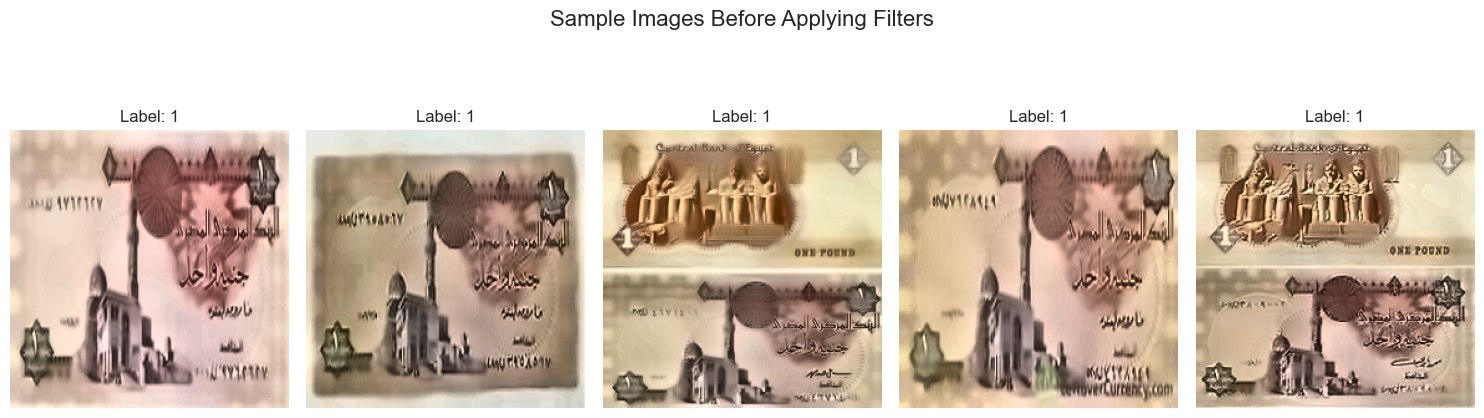

In [ ]:
original_train_images = train_images.copy()
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(original_train_images[i])  
    plt.title(f"Label: {train_labels[i]}")
    plt.axis('off')

plt.suptitle("Sample Images After Applying Filters", fontsize=16)
plt.tight_layout()
plt.show()



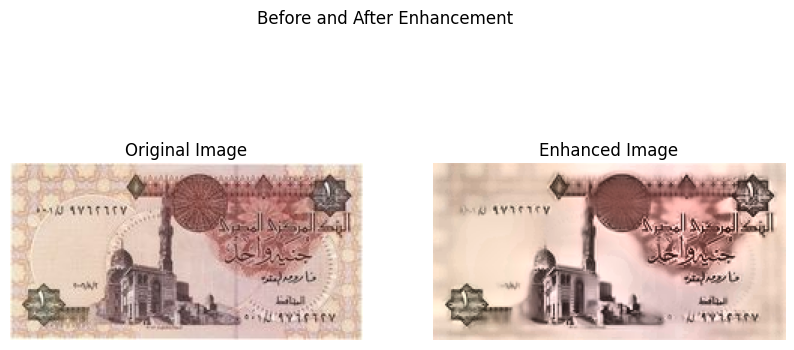

In [5]:
# Example plot of before and after enhancement
example_path = os.path.join(train_dir, class_names[0], os.listdir(os.path.join(train_dir, class_names[0]))[0])
original = Image.open(example_path).convert('RGB')
original_np = np.array(original)
enhanced = enhance_image(original_np)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(original_np)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(enhanced)
plt.title("Enhanced Image")
plt.axis('off')

plt.suptitle("Before and After Enhancement")
plt.show()

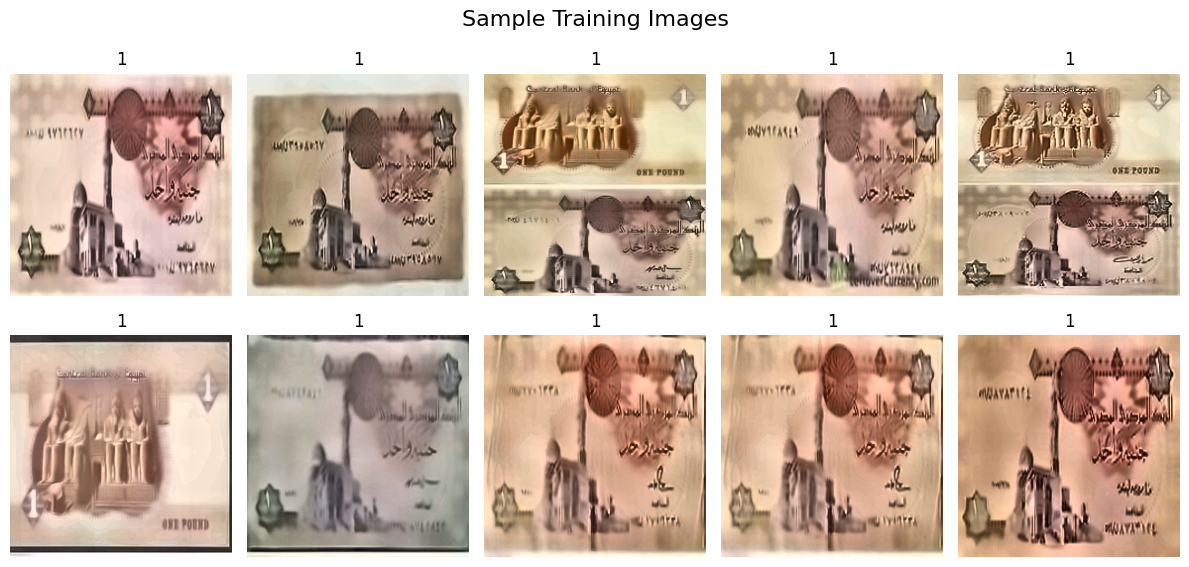

In [6]:
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(train_images[i])
    plt.title(train_labels[i])
    plt.axis('off')
plt.suptitle("Sample Training Images", fontsize=16)
plt.tight_layout()
plt.show()


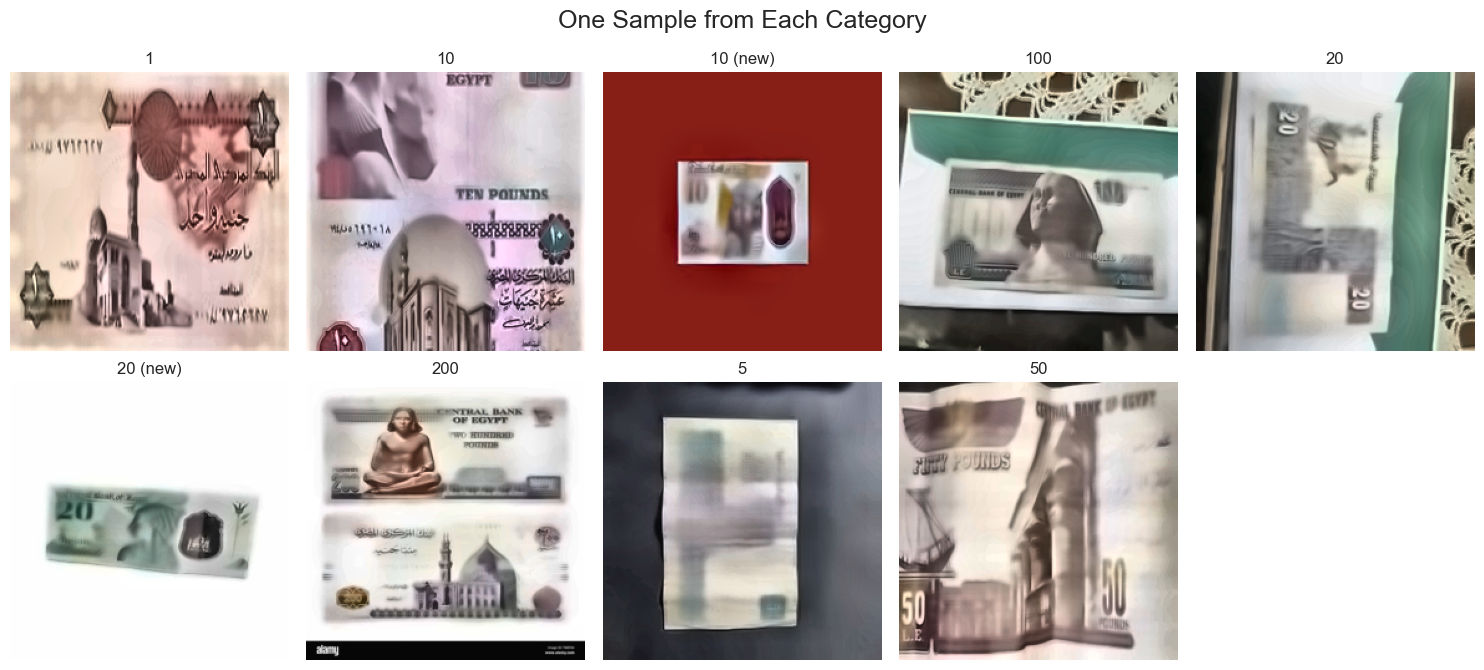

In [15]:
import numpy as np
import matplotlib.pyplot as plt

unique_classes = sorted(np.unique(train_labels))
plt.figure(figsize=(15, 7))

for idx, cls in enumerate(unique_classes):
    class_indices = np.where(train_labels == cls)[0]
    img_index = class_indices[0]  # أول صورة من الفئة
    plt.subplot(2, (len(unique_classes) + 1) // 2, idx + 1)
    plt.imshow(train_images[img_index])
    plt.title(cls)
    plt.axis('off')

plt.suptitle("One Sample from Each Category", fontsize=18)
plt.tight_layout()
plt.show()


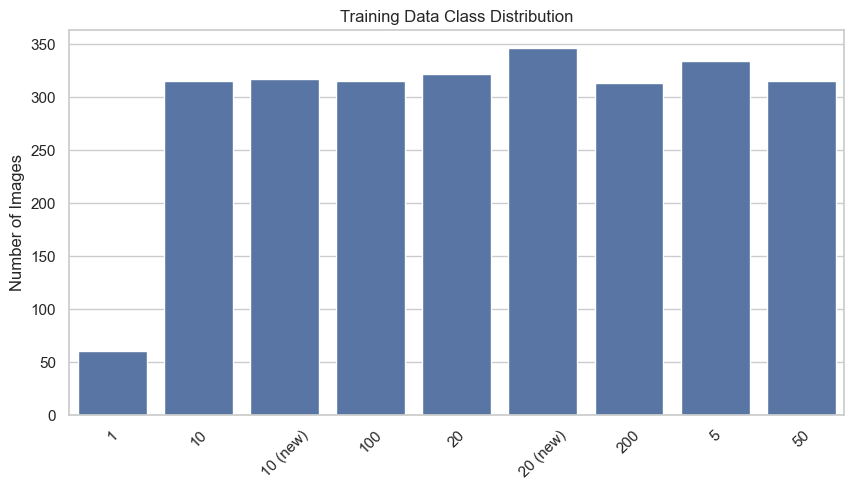

In [7]:
sns.set(style="whitegrid")
counter = Counter(train_labels)
plt.figure(figsize=(10, 5))
sns.barplot(x=list(counter.keys()), y=list(counter.values()))
plt.title("Training Data Class Distribution")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()


In [8]:
le = LabelEncoder()
train_labels_enc = to_categorical(le.fit_transform(train_labels))
val_labels_enc = to_categorical(le.transform(val_labels))
test_labels_enc = to_categorical(le.transform(test_labels))


In [9]:
class_weights = compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels)
class_weights_dict = dict(enumerate(class_weights))
print("Class Weights:", class_weights_dict)


Class Weights: {0: 4.883333333333334, 1: 0.9301587301587302, 2: 0.9242902208201893, 3: 0.9301587301587302, 4: 0.9099378881987578, 5: 0.846820809248555, 6: 0.9361022364217252, 7: 0.8772455089820359, 8: 0.9301587301587302}


In [10]:
train_datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    brightness_range=(0.7, 1.3),
    horizontal_flip=True,
    fill_mode='nearest'
)
val_datagen = ImageDataGenerator()

train_generator = train_datagen.flow(train_images, train_labels_enc, batch_size=32)
val_generator = val_datagen.flow(val_images, val_labels_enc, batch_size=32)


In [11]:
base_model = EfficientNetB3(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(len(class_names), activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)
model.compile(optimizer=Adam(learning_rate=1e-5), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │      1,080 │ stem_conv_pad[0]… │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        160 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        360 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        160 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 40)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 40)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 10)  │        410 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 40)  │        440 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 40)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        960 │ block1a_se_excit

 Total params: 10,987,576 (41.91 MB)

 Trainable params: 3,574,121 (13.63 MB)

 Non-trainable params: 7,413,455 (28.28 MB)

In [12]:
early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=30,
    callbacks=[early_stop],
    class_weight=class_weights_dict
)


Epoch 1/30


c:\Python\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


83/83 ━━━━━━━━━━━━━━━━━━━━ 174s 2s/step - accuracy: 0.1310 - loss: 3.5057 - val_accuracy: 0.1803 - val_loss: 2.1637
Epoch 2/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 149s 2s/step - accuracy: 0.1671 - loss: 3.1507 - val_accuracy: 0.2474 - val_loss: 2.0537
Epoch 3/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 146s 2s/step - accuracy: 0.1864 - loss: 2.8555 - val_accuracy: 0.3000 - val_loss: 1.9385
Epoch 4/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 162s 2s/step - accuracy: 0.2074 - loss: 2.7322 - val_accuracy: 0.3553 - val_loss: 1.8286
Epoch 5/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 143s 2s/step - accuracy: 0.2459 - loss: 2.4685 - val_accuracy: 0.3882 - val_loss: 1.7124
Epoch 6/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 136s 2s/step - accuracy: 0.2571 - loss: 2.3390 - val_accuracy: 0.4316 - val_loss: 1.5971
Epoch 7/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.2837 - loss: 2.2195 - val_accuracy: 0.4763 - val_loss: 1.4929
Epoch 8/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.3191 - loss: 2.1245 - val_accuracy: 0.5118 - val_loss: 1.

In [13]:
test_generator = val_datagen.flow(test_images, test_labels_enc, batch_size=32)
loss, acc = model.evaluate(test_generator)
print(f"Test Accuracy: {acc * 100:.2f}%")


10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 991ms/step - accuracy: 0.8769 - loss: 0.4248
Test Accuracy: 86.90%


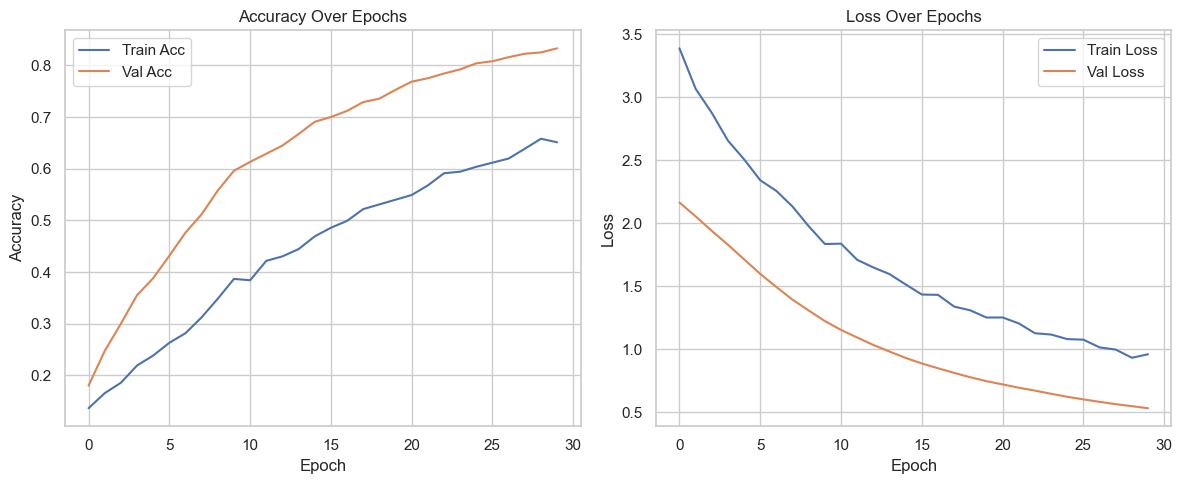

In [14]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Accuracy Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Loss Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


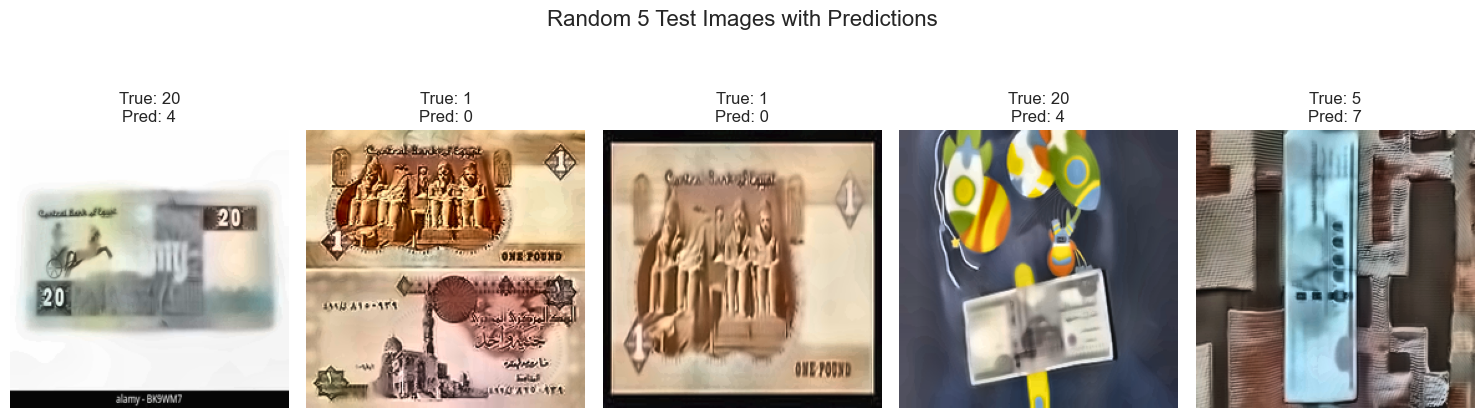

In [ ]:
import random
indices = random.sample(range(len(test_images)), 5)

plt.figure(figsize=(15, 5))
for i, idx in enumerate(indices):
    img = test_images[idx]
    true_label = test_labels[idx]
    
    pred = model.predict(np.expand_dims(img, axis=0), verbose=0)
    pred_label = np.argmax(pred)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"True: {true_label}\nPred: {pred_label}")
    plt.axis('off')

plt.suptitle("Random 5 Test Images with Predictions", fontsize=16)
plt.tight_layout()
plt.show()